## Gradient Boosting의 하이퍼파라미터 탐색

손글씨 이미지의 픽셀 값 64개로 0~9의 숫자를 분류한다. 학습률·부스팅 단계 수·트리 깊이를 조절하는 탐색 예시다.


In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.datasets import load_digits
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split,
)

SEED = 42


### 데이터 준비


In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print("입력:", X.shape, "정답:", y.shape)


입력: (1797, 64) 정답: (1797,)


### 학습·테스트 분리와 교차 검증


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED,
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
scoring = {
    "accuracy": "accuracy",
    "neg_log_loss": "neg_log_loss",
}

print("학습:", X_train.shape, "테스트:", X_test.shape)


학습: (1437, 64) 테스트: (360, 64)


### 모델과 탐색 범위

- `learning_rate`: 새 트리의 보정 결과를 반영하는 크기. 0.05~0.2에서 탐색한다.
- `n_estimators`: 보정을 반복하는 부스팅 단계 수. 30~60에서 탐색한다.
- `max_depth`: 각 보정 트리의 최대 깊이. 1~3에서 탐색한다.

이 다중 분류 모델은 단계마다 클래스별 트리를 학습한다. 학습률과 단계 수를 함께 조절하고, 깊이를 바꿔 보정 트리의 복잡도를 비교한다.

두 탐색은 같은 3개 폴드에서 각각 18개 조합을 평가한다. 평균 검증 정확도로 설정을 선택하고, log loss를 함께 기록한다.


In [4]:
base_model = GradientBoostingClassifier(
    min_samples_leaf=3,
    random_state=SEED,
)


### 그리드 탐색


In [5]:
param_grid = {
    "learning_rate": [0.05, 0.1, 0.2],
    "n_estimators": [30, 60],
    "max_depth": [1, 2, 3],
}

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring=scoring,
    cv=cv_splits,
    refit="accuracy",
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

print("선택 설정:", grid_search.best_params_)
print(f"최고 CV 정확도 평균: {grid_search.best_score_:.4f}")


선택 설정: {'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 60}
최고 CV 정확도 평균: 0.9576


### 랜덤 탐색

학습률은 0.05~0.2 범위의 연속값에서 추출한다. 로그 균등 분포는 같은 배율의 구간에 같은 확률을 부여하므로, 0.05~0.1과 0.1~0.2 구간에서 뽑힐 확률이 같다.

깊이는 1·2·3 중에서, 부스팅 단계 수는 30~60 사이의 정수에서 추출한다.


In [6]:
param_distributions = {
    # 지정한 범위에서 로그 균등 분포로 실수를 추출한다.
    "learning_rate": loguniform(0.05, 0.2),
    # 상한 61은 포함하지 않는다.
    "n_estimators": randint(30, 61),
    "max_depth": [1, 2, 3],
}

random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=18,
    random_state=SEED,
    scoring=scoring,
    cv=cv_splits,
    refit="accuracy",
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

print("선택 설정:", random_search.best_params_)
print(f"최고 CV 정확도 평균: {random_search.best_score_:.4f}")


선택 설정: {'learning_rate': np.float64(0.19285426312233855), 'max_depth': 3, 'n_estimators': 59}
최고 CV 정확도 평균: 0.9576


## 탐색 결과 비교

각 탐색이 정확도로 선택한 조합의 학습·검증 지표를 비교한다. 소요 시간에는 후보별 교차 검증과 선택한 설정의 전체 학습 데이터 재학습이 포함된다.


In [7]:
searches = {"Grid": grid_search, "Random": random_search}
elapsed = {"Grid": grid_seconds, "Random": random_seconds}
comparison_rows = []

for name, search in searches.items():
    results = search.cv_results_
    best = search.best_index_
    params = pd.DataFrame(results["params"])

    comparison_rows.append({
        "method": name,
        "evaluations": len(params),
        "unique_combinations": len(params.drop_duplicates()),
        "train_accuracy": results["mean_train_accuracy"][best],
        "cv_accuracy": results["mean_test_accuracy"][best],
        "cv_accuracy_std": results["std_test_accuracy"][best],
        # 정확도로 선택한 같은 조합의 손실을 원래 부호로 표시한다.
        "train_log_loss": -results["mean_train_neg_log_loss"][best],
        "cv_log_loss": -results["mean_test_neg_log_loss"][best],
        "seconds": elapsed[name],
    })

comparison = pd.DataFrame(comparison_rows)
comparison["accuracy_gap"] = comparison["train_accuracy"] - comparison["cv_accuracy"]
display(comparison.round(4))


,method,evaluations,unique_combinations,train_accuracy,cv_accuracy,cv_accuracy_std,train_log_loss,cv_log_loss,seconds,accuracy_gap
0,Grid,18,18,1.0,0.9576,0.0077,0.0051,0.1495,41.0736,0.0424
1,Random,18,18,1.0,0.9576,0.0081,0.0001,0.1576,43.0427,0.0424


### 탐색 횟수에 따른 결과 비교

각 지점까지 발견한 최고 평균 검증 정확도를 표시한다. 곡선은 후보를 평가한 순서에 영향을 받으며, 평가 횟수가 같아도 단계 수와 깊이에 따라 소요 시간은 달라질 수 있다.


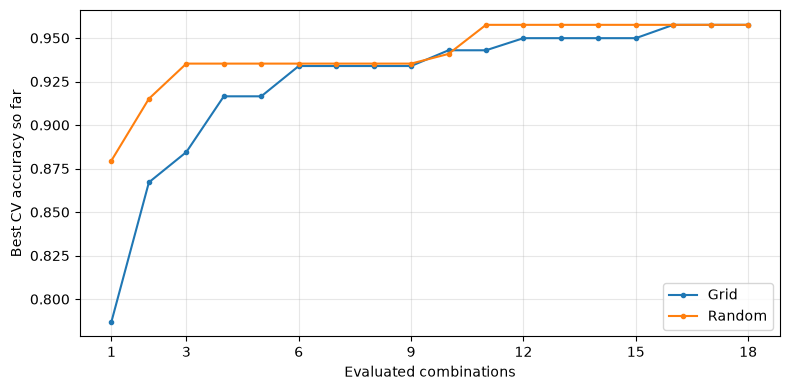

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, search in searches.items():
    scores = search.cv_results_["mean_test_accuracy"]
    best_so_far = np.maximum.accumulate(scores)
    ax.plot(
        np.arange(1, len(scores) + 1), best_so_far,
        marker=".", label=name,
    )

ax.set(xlabel="Evaluated combinations", ylabel="Best CV accuracy so far")
ax.set_xticks([1, 3, 6, 9, 12, 15, 18])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 결과 해석과 모델 선택

두 탐색의 검증 정확도는 비슷하지만 선택한 학습률·깊이·부스팅 단계 수는 서로 다르다. 랜덤 탐색은 학습 log loss가 더 낮고, 그리드 탐색은 검증 log loss가 더 낮다.

모델 선택 기준은 평균 검증 정확도이며, 동점이면 표의 첫 번째 설정을 사용한다. 이번 실행에서는 그리드 탐색의 설정이 선택된다.

탐색 결과에는 후보 범위와 추출된 조합의 영향이 함께 반영된다. 이번 비교의 해석 범위는 지정한 데이터 분할·후보 구성·난수 시드로 한정한다.


In [9]:
selected_name = comparison.loc[comparison["cv_accuracy"].idxmax(), "method"]
selected_search = searches[selected_name]

# 선택한 설정으로 전체 학습 데이터를 재학습한 모델을 사용한다.
selected_model = selected_search.best_estimator_
print("선택한 방법:", selected_name)
print("선택한 설정:", selected_search.best_params_)


선택한 방법: Grid
선택한 설정: {'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 60}


### 최종 테스트


In [10]:
final_rows = []
for split, inputs, actual in [
    ("train", X_train, y_train),
    ("test", X_test, y_test),
]:
    prediction = selected_model.predict(inputs)
    probability = selected_model.predict_proba(inputs)
    final_rows.append({
        "split": split,
        "accuracy": accuracy_score(actual, prediction),
        "log_loss": log_loss(actual, probability, labels=selected_model.classes_),
    })

display(pd.DataFrame(final_rows))


,split,accuracy,log_loss
0,train,1.000000,0.008833
1,test,0.963889,0.135902
